# Лабораторная работа: Reducerea dimensionalității — снижение размерности данных

## Цель
Уменьшить число признаков набора данных о недвижимости, сохранив как можно больше значимой информации, визуализировать многомерные данные в 2D и сравнить методы **PCA**, **t-SNE**, **UMAP** и **TruncatedSVD**.

## Задачи
1. Изучить и подготовить данные (дубликаты, пропуски, категории, масштаб).
2. Применить PCA: объяснённая дисперсия, выбор числа компонент, интерпретация компонент.
3. Получить 2D-представления t-SNE и UMAP.
4. Показать TruncatedSVD и объяснить его отличие от PCA.
5. Сравнить методы таблицей и *расчётными* показателями, а не только на глаз.
6. Проверить, упрощает ли снижение размерности последующую кластеризацию.

**Файл данных:** `real_estate_regression_dataset.csv`. Исходный файл не изменяется.

## Теоретические основы

**Проклятие размерности.** Чем больше признаков, тем «разреженнее» пространство: расстояния между объектами становятся похожими, модели и визуализации хуже работают, вычисления дороже. Многие признаки при этом дублируют друг друга (например, площадь и число спален).

**Отбор признаков (Feature Selection) и снижение размерности (Dimensionality Reduction).**
- *Отбор признаков* оставляет **часть исходных столбцов** и выбрасывает остальные. Смысл признаков сохраняется («остались площадь и качество»).
- *Снижение размерности* строит **новые признаки** (компоненты) как комбинации всех исходных. Информации сохраняется больше, но новые признаки уже не имеют прямого физического смысла. Основной акцент этой работы — на нём.

**Методы работы:**
- **PCA** — линейно поворачивает оси так, чтобы первая ось захватывала максимум разброса данных, вторая — максимум оставшегося и т. д. Сохраняет *глобальную* структуру; результат можно измерять долей объяснённой дисперсии.
- **t-SNE** — нелинейный метод для визуализации: старается, чтобы близкие в исходном пространстве объекты остались близкими на плоскости. Хорошо показывает *локальную* структуру, но расстояния между группами и размеры групп на картинке интерпретировать нельзя.
- **UMAP** — нелинейный метод, похожий на t-SNE по идее (граф ближайших соседей), обычно быстрее и лучше сохраняет часть глобальной структуры.
- **TruncatedSVD** — близок к PCA, но **не центрирует данные**; поэтому работает с разреженными матрицами (например, после one-hot кодирования).

## Импорт библиотек и загрузка данных
Подключаем библиотеки и проверяем, что файл существует. Для UMAP нужна библиотека `umap-learn` (реализует алгоритм UMAP; в scikit-learn его нет).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # убирает ложные предупреждения macOS
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE, trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

# UMAP — отдельная библиотека; если её нет, продолжаем без неё
try:
    import umap
    HAS_UMAP = True
except Exception as e:
    HAS_UMAP = False
    UMAP_ERROR = repr(e)
    print("UMAP недоступен:", UMAP_ERROR)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
print("UMAP доступен:", HAS_UMAP)

UMAP доступен: True


In [2]:
# Данные лежат в папке data/ рядом с папкой notebooks/
DATA_PATH = Path("../data/real_estate_regression_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Файл данных не найден. Проверьте, что он лежит в папке data/.")
print("Файл найден:", DATA_PATH)

# Папка для результатов
OUT_DIR = Path("../outputs/dimensionality_reduction")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Папка результатов:", OUT_DIR)

df_raw = pd.read_csv(DATA_PATH)       # исходные данные, дальше не изменяются
print("Строк:", df_raw.shape[0], "| Столбцов:", df_raw.shape[1])
df_raw.head()

Файл найден: ../data/real_estate_regression_dataset.csv
Папка результатов: ../outputs/dimensionality_reduction
Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


## Первичный EDA
Смотрим типы данных, пропуски, дубликаты, распределения числовых признаков и выбросы.

In [3]:
info = pd.DataFrame({"тип": df_raw.dtypes, "пропусков": df_raw.isna().sum(),
                     "доля пропусков, %": (df_raw.isna().mean() * 100).round(1),
                     "уникальных": df_raw.nunique()})
print(info.to_string())
print("\nПолных дубликатов:", df_raw.duplicated().sum())

                       тип  пропусков  доля пропусков, %  уникальных
Id                   int64          0                0.0        2800
Neighborhood        object          0                0.0          13
PropertyType        object          0                0.0           6
OverallQual          int64          0                0.0          10
Condition           object        145                5.1           6
RenovationQuality   object        245                8.6           3
GrLivArea            int64          0                0.0         281
LotArea            float64        145                5.1         832
TotalBsmtSF        float64        249                8.8         205
Rooms                int64          0                0.0          10
Bedrooms             int64          0                0.0          11
Bathrooms            int64          0                0.0           7
Floor                int64          0                0.0          19
TotalFloors          int64        

In [4]:
# Основные статистики и асимметрия (skew) числовых признаков; |skew| > 1 — сильно скошенное распределение
num_all = df_raw.select_dtypes(include="number").columns.drop(["Id"])
stats = df_raw[num_all].describe().T
stats["skew"] = df_raw[num_all].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
OverallQual,2840.0,6.11,1.60,1.0,5.0,6.0,7.0,10.0,-0.03
GrLivArea,2840.0,128.94,59.01,29.0,84.0,120.0,159.0,538.0,1.47
LotArea,2695.0,338.03,556.10,0.0,0.0,221.0,463.5,11197.0,8.49
TotalBsmtSF,2591.0,55.40,56.50,0.0,0.0,53.0,92.0,449.0,1.00
Rooms,2840.0,5.39,1.79,2.0,4.0,5.0,6.0,11.0,0.47
Bedrooms,2840.0,3.42,1.61,1.0,2.0,3.0,4.0,12.0,0.72
Bathrooms,2840.0,2.24,1.05,1.0,1.0,2.0,3.0,7.0,0.73
Floor,2840.0,2.56,3.31,1.0,1.0,1.0,2.0,19.0,2.53
TotalFloors,2840.0,4.77,5.13,1.0,2.0,2.0,7.0,19.0,1.46
YearBuilt,2840.0,1988.79,20.98,1890.0,1975.0,1989.0,2004.0,2024.0,-0.32


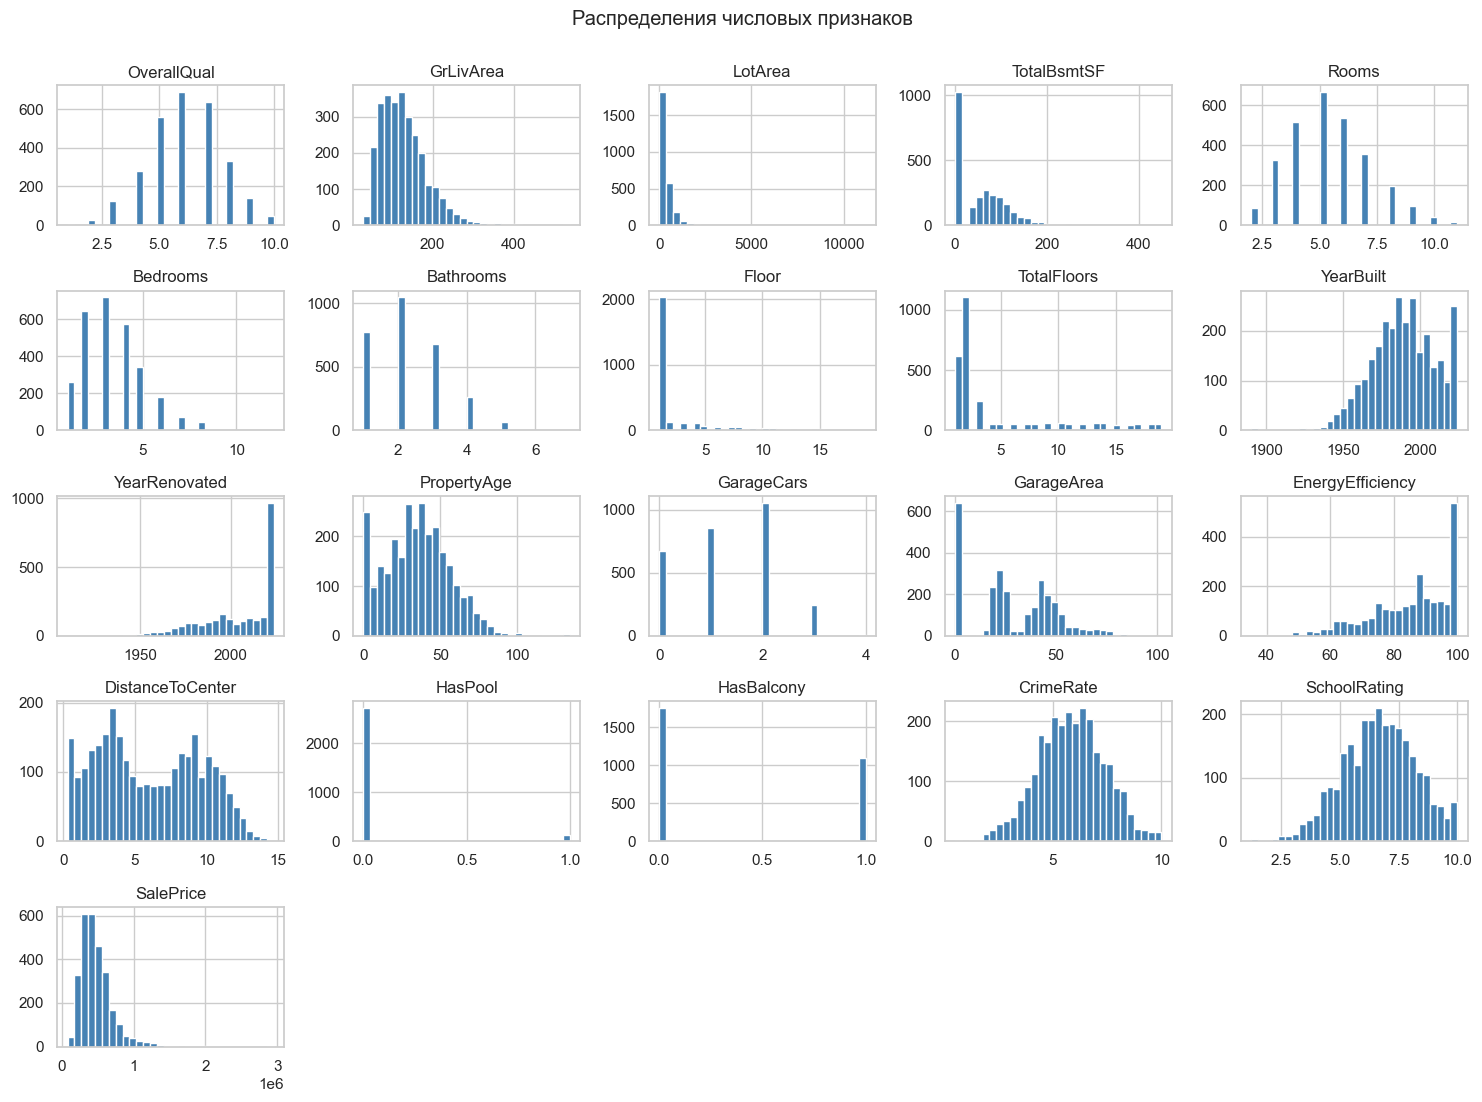

In [5]:
# Гистограммы числовых признаков (кроме Id)
df_raw[num_all].hist(bins=30, figsize=(15, 11), color="steelblue")
plt.suptitle("Распределения числовых признаков", y=1.0)
plt.tight_layout()
plt.show()

**Что видно:** часть признаков (площади, цена) сильно скошена вправо — есть «хвост» очень больших и дорогих объектов; бинарные признаки (`HasPool`, `HasBalcony`) принимают только 0 и 1. Выбросы нужно учитывать: PCA основан на дисперсии и чувствителен к ним.

## Очистка и подготовка признаков

1. **Дубликаты** удаляем: повтор одной и той же строки не несёт новой информации и «утяжеляет» этот объект.
2. **Пропуски** заполняем: числовые — медианой (устойчива к выбросам), категориальные — наиболее частым значением. Удалять строки с пропусками нельзя — потеряли бы слишком много данных.
3. **Выбросы** не удаляем: это реальные дорогие и крупные объекты; их влияние обсудим при интерпретации.
4. **Исключаем из признаков:**
   - `Id` — просто номер строки, информации не несёт;
   - `SalePrice` — целевая переменная; в основной набор не включаем, используем только для окрашивания и интерпретации *после* преобразования;
   - `YearBuilt` — точная копия `PropertyAge` (`PropertyAge = 2024 − YearBuilt`, корреляция −1), оставляем один из двух.

In [6]:
# Удаление дубликатов и заполнение пропусков
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {len(df_raw) - len(df)}. Осталось строк: {len(df)}")

# Проверка: YearBuilt и PropertyAge — одна и та же информация
print("Корреляция YearBuilt и PropertyAge:", round(df_raw["YearBuilt"].corr(df_raw["PropertyAge"]), 3))

num_cols = [c for c in df.select_dtypes(include="number").columns if c not in ("Id", "SalePrice", "YearBuilt")]
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Пропусков после заполнения:", int(df[num_cols + cat_cols].isna().sum().sum()))
print("\nЧисловых признаков:", len(num_cols), "|", num_cols)
print("Категориальных признаков:", len(cat_cols), "|", cat_cols)

Удалено дубликатов: 40. Осталось строк: 2800
Корреляция YearBuilt и PropertyAge: -1.0
Пропусков после заполнения: 0

Числовых признаков: 19 | ['OverallQual', 'GrLivArea', 'LotArea', 'TotalBsmtSF', 'Rooms', 'Bedrooms', 'Bathrooms', 'Floor', 'TotalFloors', 'YearRenovated', 'PropertyAge', 'GarageCars', 'GarageArea', 'EnergyEfficiency', 'DistanceToCenter', 'HasPool', 'HasBalcony', 'CrimeRate', 'SchoolRating']
Категориальных признаков: 6 | ['Neighborhood', 'PropertyType', 'Condition', 'RenovationQuality', 'GarageType', 'HeatingType']


## Масштабирование и формирование матрицы признаков

- **Категориальные** признаки кодируем one-hot (каждая категория — столбец 0/1). Это нужно, потому что PCA, t-SNE и UMAP работают только с числами.
- **Числовые** признаки масштабируем `StandardScaler` (среднее 0, стандартное отклонение 1). PCA чувствителен к масштабу: без этого признаки с большими числами (площадь участка) «перетянули бы» компоненты на себя.
- One-hot столбцы оставляем как 0/1: они уже находятся в сопоставимом масштабе.
- Для всех методов используем **одну и ту же матрицу** `X` и одни и те же объекты, чтобы сравнение было корректным.

In [7]:
# Числовые признаки -> стандартизация
X_num = StandardScaler().fit_transform(df[num_cols])

# Категориальные признаки -> one-hot (разреженная матрица и обычная версия)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
X_cat_sp = ohe.fit_transform(df[cat_cols])
cat_names = ohe.get_feature_names_out(cat_cols).tolist()

# Итоговая матрица признаков: числа + one-hot
X = np.hstack([X_num, X_cat_sp.toarray()])
feature_names = num_cols + cat_names
print("Форма матрицы признаков X:", X.shape, "(объектов x признаков)")
print("Из них числовых:", len(num_cols), "| one-hot:", len(cat_names))

# Сохраняем подготовленный набор отдельно от исходного
prepared = pd.DataFrame(X, columns=feature_names)
prepared["SalePrice"] = df["SalePrice"].values      # только для интерпретации, в методы не передаётся
prepared.to_csv(OUT_DIR / "real_estate_prepared_for_dr.csv", index=False)
print("Сохранено:", OUT_DIR / "real_estate_prepared_for_dr.csv")

Форма матрицы признаков X: (2800, 60) (объектов x признаков)
Из них числовых: 19 | one-hot: 41
Сохранено: ../outputs/dimensionality_reduction/real_estate_prepared_for_dr.csv


In [8]:
# Целевая переменная — только для окраски графиков ПОСЛЕ преобразования (в алгоритмы не передаётся)
price = df["SalePrice"].values
log_price = np.log10(price)      # логарифм, чтобы выбросы не «съедали» цветовую шкалу

## PCA и анализ объяснённой дисперсии
**Идея простыми словами:** представьте облако точек в 60-мерном пространстве. PCA находит направление, вдоль которого облако вытянуто сильнее всего (первая компонента), затем следующее направление под прямым углом и т. д. Если первые несколько направлений описывают почти весь разброс, остальные можно отбросить.

Сначала считаем PCA со всеми компонентами, чтобы увидеть, сколько информации даёт каждая.

In [9]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Исходных признаков: {X.shape[1]}")
print(f"Компонент для 90% дисперсии: {n90}")
print(f"Компонент для 95% дисперсии: {n95}")
print(f"Доля дисперсии у первых 2 компонент: {cum[1]:.3f}")
print("\nПервые 10 компонент:")
print(pd.DataFrame({"доля": evr[:10], "накопленная": cum[:10]},
                   index=[f"PC{i+1}" for i in range(10)]).round(3).to_string())

Исходных признаков: 60
Компонент для 90% дисперсии: 23
Компонент для 95% дисперсии: 31
Доля дисперсии у первых 2 компонент: 0.326

Первые 10 компонент:
       доля  накопленная
PC1   0.230        0.230
PC2   0.097        0.326
PC3   0.085        0.411
PC4   0.062        0.473
PC5   0.059        0.532
PC6   0.042        0.574
PC7   0.040        0.614
PC8   0.037        0.651
PC9   0.034        0.685
PC10  0.033        0.717


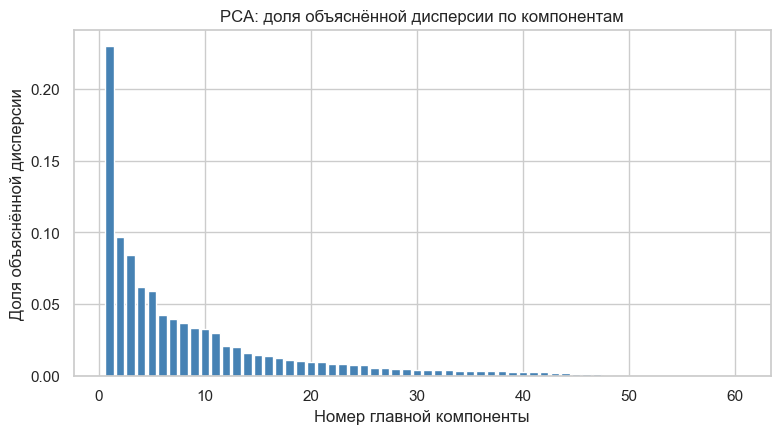

In [10]:
# График 1: объяснённая дисперсия по компонентам
plt.figure(figsize=(9, 4.5))
plt.bar(range(1, len(evr) + 1), evr, color="steelblue")
plt.title("PCA: доля объяснённой дисперсии по компонентам")
plt.xlabel("Номер главной компоненты")
plt.ylabel("Доля объяснённой дисперсии")
plt.show()

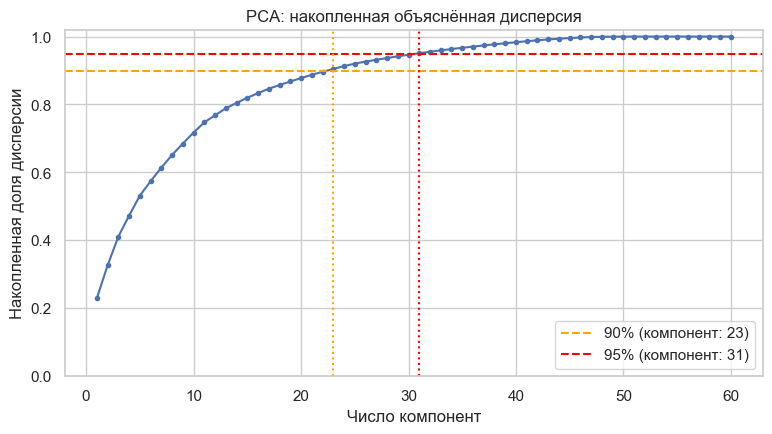

In [11]:
# График 2: накопленная объяснённая дисперсия с порогами 90% и 95%
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(cum) + 1), cum, "o-", markersize=3)
plt.axhline(0.90, color="orange", ls="--", label=f"90% (компонент: {n90})")
plt.axhline(0.95, color="red", ls="--", label=f"95% (компонент: {n95})")
plt.axvline(n90, color="orange", ls=":")
plt.axvline(n95, color="red", ls=":")
plt.title("PCA: накопленная объяснённая дисперсия")
plt.xlabel("Число компонент")
plt.ylabel("Накопленная доля дисперсии")
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.show()

**Как читать:** первый график показывает, сколько информации даёт каждая компонента (резкое падение — «локоть», после него компоненты приносят мало). Второй — сколько компонент нужно, чтобы сохранить 90% и 95% разброса. Это и есть ответ на вопрос «на сколько можно сократить данные». Выбор числа компонент — всегда компромисс между сжатием и потерей информации.

## Визуализация PCA
Строим данные в пространстве первых двух компонент. Окраска по цене — **только дополнительная визуализация**: PCA не видел цену и не обучался её предсказывать.

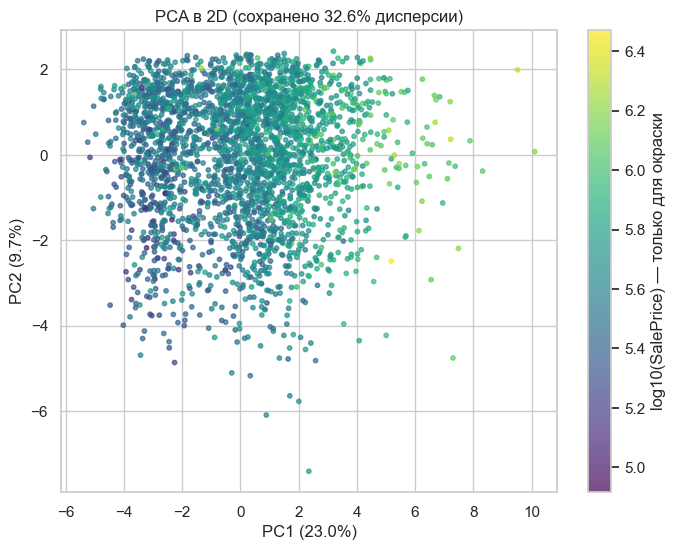

In [12]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca2.fit_transform(X)

plt.figure(figsize=(8, 6))
sc = plt.scatter(Z_pca[:, 0], Z_pca[:, 1], c=log_price, cmap="viridis", s=10, alpha=0.7)
plt.colorbar(sc, label="log10(SalePrice) — только для окраски")
plt.title(f"PCA в 2D (сохранено {pca2.explained_variance_ratio_.sum() * 100:.1f}% дисперсии)")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1] * 100:.1f}%)")
plt.show()

### Что означают компоненты
Каждая компонента — это **взвешенная сумма всех исходных признаков**, а не один признак. Веса называются *нагрузками* (loadings): чем больше по модулю нагрузка, тем сильнее признак влияет на компоненту. Поэтому компонента не обязательно соответствует одному исходному признаку: она описывает *согласованное изменение группы признаков* (например, «большие объекты: много площади, спален и ванных сразу»).

In [13]:
# Нагрузки первых компонент: какие признаки вносят наибольший вклад
loadings = pd.DataFrame(pca_full.components_[:4].T, index=feature_names, columns=[f"PC{i+1}" for i in range(4)])
for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(pc, "->", ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top))

PC1 -> GrLivArea (+0.38), Bedrooms (+0.38), Rooms (+0.35), TotalBsmtSF (+0.34), Bathrooms (+0.32), TotalFloors (-0.31)
PC2 -> YearRenovated (+0.60), EnergyEfficiency (+0.57), PropertyAge (-0.54), DistanceToCenter (+0.06), SchoolRating (-0.04), HasBalcony (-0.02)
PC3 -> GarageArea (+0.65), GarageCars (+0.65), GarageType_NoGarage (-0.20), Bathrooms (-0.15), Bedrooms (-0.15), Rooms (-0.14)
PC4 -> DistanceToCenter (+0.55), SchoolRating (-0.37), CrimeRate (+0.32), OverallQual (-0.32), Floor (-0.28), TotalFloors (-0.25)


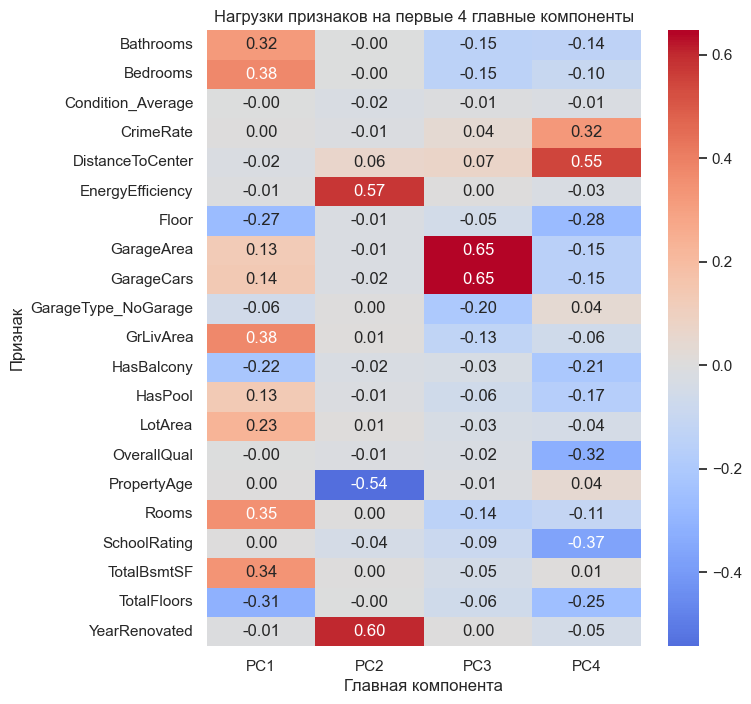

In [14]:
# Тепловая карта нагрузок: по 8 самых важных признаков для каждой из первых 4 компонент
top_feats = sorted(set(sum([loadings[pc].abs().sort_values(ascending=False).head(8).index.tolist() for pc in loadings.columns], [])))
plt.figure(figsize=(7, 8))
sns.heatmap(loadings.loc[top_feats], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Нагрузки признаков на первые 4 главные компоненты")
plt.xlabel("Главная компонента")
plt.ylabel("Признак")
plt.show()

In [15]:
# Дополнительная интерпретация: связь компонент с ценой (цена в PCA не участвовала)
pcs = pca_full.transform(X)[:, :4]
corr_price = pd.Series([np.corrcoef(pcs[:, i], log_price)[0, 1] for i in range(4)],
                       index=[f"PC{i+1}" for i in range(4)])
print("Корреляция компонент с log10(SalePrice):")
print(corr_price.round(3).to_string())

Корреляция компонент с log10(SalePrice):
PC1    0.637
PC2    0.146
PC3   -0.132
PC4   -0.490


## t-SNE и его визуализация
**Идея простыми словами:** t-SNE для каждой пары объектов оценивает «вероятность быть соседями» в исходном пространстве и старается воспроизвести эти вероятности на плоскости. Поэтому близкие объекты остаются рядом, но удалённые группы могут быть расставлены произвольно.

**Отличие от PCA:** PCA — линейный и сохраняет глобальную форму; t-SNE — нелинейный и сохраняет локальных соседей, но не даёт «объяснённой дисперсии».

**Параметры:** `perplexity` — примерное число «соседей» у каждого объекта (типично 5–50); `random_state=42` — фиксируем случайность; `init="pca"` — стартуем с PCA, это стабильнее. Исследуем три значения `perplexity`.

In [16]:
# t-SNE с тремя значениями perplexity (на всех 2800 объектах; займёт около минуты)
tsne_results = {}
tsne_time = {}
for perp in (5, 30, 50):
    t0 = time.time()
    tsne_results[perp] = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
                              random_state=RANDOM_STATE).fit_transform(X)
    tsne_time[perp] = time.time() - t0
    print(f"perplexity={perp}: {tsne_time[perp]:.1f} сек")

perplexity=5: 3.9 сек
perplexity=30: 4.2 сек
perplexity=50: 4.7 сек


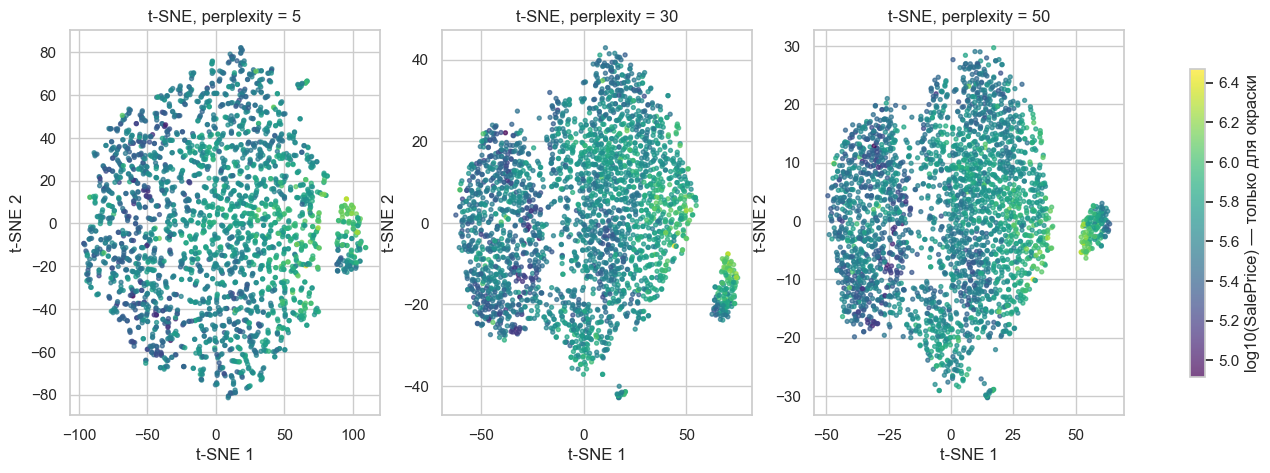

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (perp, Z) in zip(axes, tsne_results.items()):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=log_price, cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"t-SNE, perplexity = {perp}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
fig.colorbar(sc, ax=axes, label="log10(SalePrice) — только для окраски", shrink=0.8)
plt.show()

**Как читать:** при разных `perplexity` картинка меняется — это нормально и показывает, что форму групп на t-SNE нельзя считать «истиной». Размеры групп и расстояния между далёкими группами **не** соответствуют исходным расстояниям. t-SNE не доказывает существование кластеров: он способен рисовать «острова» и в данных без кластеров. Для дальнейшего сравнения берём `perplexity=30`.

In [18]:
Z_tsne = tsne_results[30]

## UMAP и его визуализация
**Идея простыми словами:** UMAP строит граф «кто чей ближайший сосед», а затем раскладывает этот граф на плоскости так, чтобы связи сохранились. По идее похож на t-SNE, но обычно быстрее и лучше сохраняет общую расстановку групп.

**Параметры:** `n_neighbors=15` (размер локального окружения; больше — более глобальная картина), `min_dist=0.1` (насколько плотно точки могут «слипаться»), `random_state=42`.

UMAP выполнен за 6.1 сек


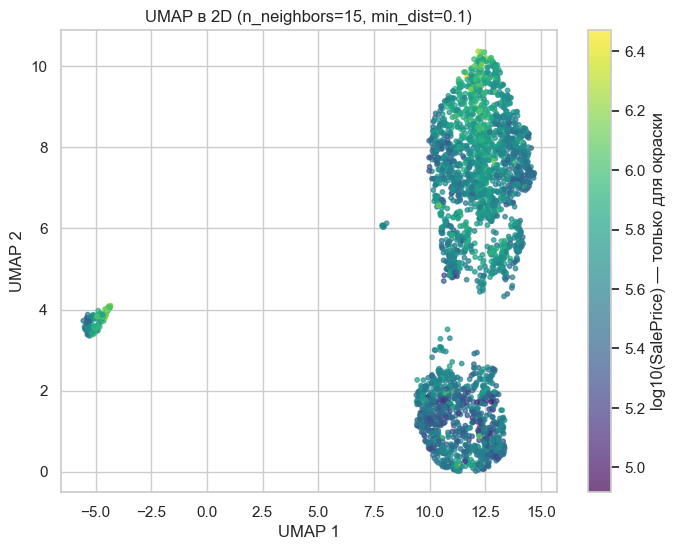

In [19]:
if HAS_UMAP:
    t0 = time.time()
    Z_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X)
    umap_time = time.time() - t0
    print(f"UMAP выполнен за {umap_time:.1f} сек")

    plt.figure(figsize=(8, 6))
    sc = plt.scatter(Z_umap[:, 0], Z_umap[:, 1], c=log_price, cmap="viridis", s=10, alpha=0.7)
    plt.colorbar(sc, label="log10(SalePrice) — только для окраски")
    plt.title("UMAP в 2D (n_neighbors=15, min_dist=0.1)")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.show()
else:
    Z_umap = None
    print("UMAP пропущен. Причина:", UMAP_ERROR)
    print("Установите библиотеку командой: !pip install umap-learn  — и перезапустите ядро.")

## TruncatedSVD
**Отличие от PCA:** PCA сначала вычитает среднее (центрирует данные), `TruncatedSVD` — нет. Поэтому он работает с **разреженными матрицами** (где большинство значений — нули) и не «ломает» разреженность центрированием.

**Есть ли смысл в этом датасете?** Да, ограниченный: категориальные признаки после one-hot кодирования образуют разреженную матрицу (около 41 столбца, из них в каждой строке единицы только у 6). Покажем SVD на этой разреженной матрице и сравним с PCA на тех же данных. Что можно ожидать: у SVD одна из компонент «ловит» ненулевое среднее (из-за отсутствия центрирования) и почти не несёт дисперсии, поэтому порядок и доли компонент могут отличаться от PCA. Здесь числовая часть уже стандартизована (центрирована), поэтому различие будет небольшим; проверим это расчётом.

In [20]:
# Разреженная матрица: числа (стандартизованные) + one-hot
X_sp = sparse.hstack([sparse.csr_matrix(X_num), X_cat_sp]).tocsr()
print("Доля нулевых элементов в one-hot части:", round(1 - X_cat_sp.nnz / (X_cat_sp.shape[0] * X_cat_sp.shape[1]), 3))

svd = TruncatedSVD(n_components=20, random_state=RANDOM_STATE).fit(X_sp)
svd_evr = svd.explained_variance_ratio_
print("TruncatedSVD, доля объяснённой дисперсии (первые 5):", svd_evr[:5].round(3))
print("PCA,          доля объяснённой дисперсии (первые 5):", evr[:5].round(3))
print(f"\nСумма для 2 компонент: SVD = {svd_evr[:2].sum():.3f}, PCA = {evr[:2].sum():.3f}")

# Проверка: на центрированных данных SVD должен дать то же, что PCA
X_centered = X - X.mean(axis=0)
svd_c = TruncatedSVD(n_components=5, random_state=RANDOM_STATE).fit(X_centered)
print("SVD на центрированных данных (первые 5):", svd_c.explained_variance_ratio_.round(3))

Доля нулевых элементов в one-hot части: 0.854
TruncatedSVD, доля объяснённой дисперсии (первые 5): [0.23  0.097 0.085 0.003 0.062]
PCA,          доля объяснённой дисперсии (первые 5): [0.23  0.097 0.085 0.062 0.059]

Сумма для 2 компонент: SVD = 0.326, PCA = 0.326
SVD на центрированных данных (первые 5): [0.23  0.097 0.085 0.062 0.059]


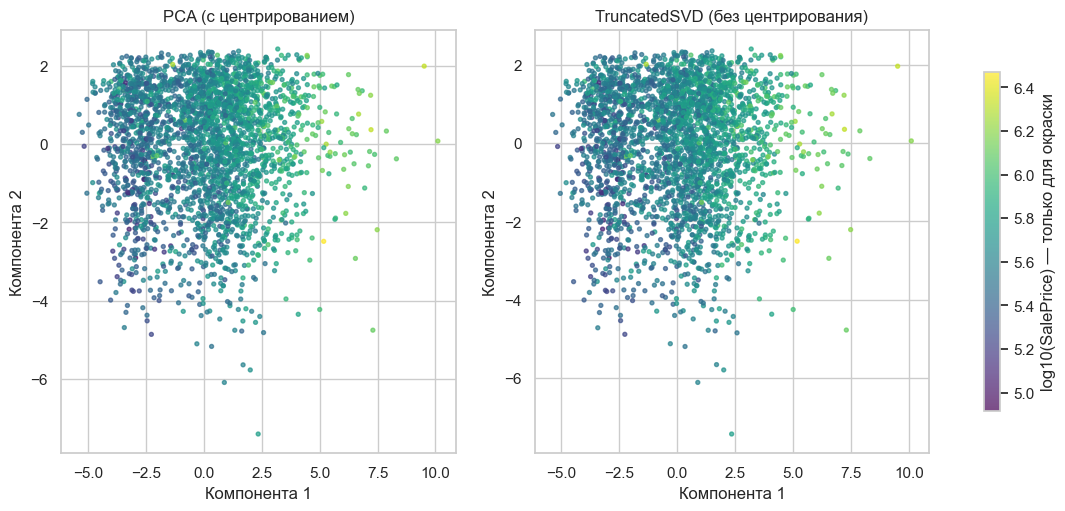

In [21]:
Z_svd = svd.transform(X_sp)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, Z, t in zip(axes, [Z_pca, Z_svd], ["PCA (с центрированием)", "TruncatedSVD (без центрирования)"]):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=log_price, cmap="viridis", s=8, alpha=0.7)
    ax.set_title(t)
    ax.set_xlabel("Компонента 1")
    ax.set_ylabel("Компонента 2")
fig.colorbar(sc, ax=axes, label="log10(SalePrice) — только для окраски", shrink=0.8)
plt.show()

**Как читать результат:** в списке долей SVD есть компонента с почти нулевой дисперсией (в моём запуске это 4-я, доля 0.003) — это и есть «компонента среднего», которой нет у PCA; остальные компоненты и двумерная картинка совпадают с PCA. На центрированных данных `TruncatedSVD` в точности совпадает с PCA — различие только в центрировании. Для данной таблицы (она небольшая и помещается в память целиком) преимущества SVD в скорости и памяти не нужны; метод оправдан, прежде всего, как демонстрация и для сценариев с большими разреженными данными (тексты, матрицы «пользователь–товар»).

## Сравнение результатов
Сравнивать методы только по объяснённой дисперсии нельзя: у t-SNE и UMAP такой метрики нет. Поэтому добавляем две расчётные характеристики:

- **Trustworthiness (надёжность окрестностей, 0–1)** — доля «настоящих» ближайших соседей, сохранённых в 2D (*локальная структура*). Выше — лучше.
- **Корреляция расстояний (Spearman)** — совпадение попарных расстояний в 2D и в исходном пространстве на выборке из 700 объектов (*глобальная структура*). Выше — лучше.

In [22]:
# Выборка объектов для оценки глобальной структуры
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X), 700, replace=False)
d_orig = pdist(X[idx])

def evaluate(Z):
    tw = trustworthiness(X, Z, n_neighbors=10)
    gl = spearmanr(d_orig, pdist(Z[idx]))[0]
    return round(tw, 3), round(gl, 3)

emb = {"PCA (2D)": Z_pca, "t-SNE (2D, perplexity=30)": Z_tsne, "TruncatedSVD (2D)": Z_svd}
if Z_umap is not None:
    emb["UMAP (2D)"] = Z_umap

scores = pd.DataFrame({name: evaluate(Z) for name, Z in emb.items()}, index=["Trustworthiness", "Корреляция расстояний"]).T
scores

,Trustworthiness,Корреляция расстояний
PCA (2D),0.809,0.754
"t-SNE (2D, perplexity=30)",0.959,0.639
TruncatedSVD (2D),0.809,0.754
UMAP (2D),0.916,0.659


In [23]:
# Итоговая сравнительная таблица методов
qual = {
    "PCA (2D)": ("линейный", "хорошо сохраняет глобальную структуру, локальную — частично",
                 "быстрый, интерпретируемые нагрузки, обратимый, есть объяснённая дисперсия",
                 "только линейные зависимости, чувствителен к масштабу и выбросам",
                 "сжатие признаков, предобработка перед моделями, поиск главных факторов"),
    "t-SNE (2D, perplexity=30)": ("нелинейный", "хорошо сохраняет локальные окрестности, глобальную — плохо",
                 "наглядная 2D-карта локальной структуры",
                 "медленный, зависит от perplexity и случайности, расстояния между группами не интерпретируются, нет transform для новых данных",
                 "визуальное исследование структуры; не для количественных выводов"),
    "UMAP (2D)": ("нелинейный", "хорошо сохраняет локальную и частично глобальную структуру",
                 "быстрее t-SNE, масштабируется на большие данные, есть transform для новых данных",
                 "зависит от n_neighbors и min_dist, результат трудно интерпретировать количественно",
                 "визуализация больших данных, предобработка перед кластеризацией (с осторожностью)"),
    "TruncatedSVD (2D)": ("линейный", "как PCA, но без центрирования",
                 "работает с разреженными матрицами, экономит память",
                 "без центрирования первая компонента отражает среднее; дисперсии не совпадают с PCA",
                 "тексты (LSA), разреженные матрицы, рекомендательные системы"),
}
var2 = {"PCA (2D)": f"{evr[:2].sum():.3f}", "TruncatedSVD (2D)": f"{svd_evr[:2].sum():.3f}",
        "t-SNE (2D, perplexity=30)": "не применима", "UMAP (2D)": "не применима"}

rows = []
for name in emb:
    typ, struct, pros, cons, tasks = qual[name]
    rows.append({"Метод": name, "Тип": typ, "Исходных признаков": X.shape[1], "Компонент": 2,
                 "Объяснённая дисперсия": var2[name],
                 "Trustworthiness": scores.loc[name, "Trustworthiness"],
                 "Корр. расстояний": scores.loc[name, "Корреляция расстояний"],
                 "Структура": struct, "Преимущества": pros, "Ограничения": cons, "Задачи": tasks})
comparison = pd.DataFrame(rows).set_index("Метод")
comparison.to_csv(OUT_DIR / "methods_comparison.csv")
comparison[["Тип", "Исходных признаков", "Компонент", "Объяснённая дисперсия", "Trustworthiness", "Корр. расстояний"]]

,Тип,Исходных признаков,Компонент,Объяснённая дисперсия,Trustworthiness,Корр. расстояний
Метод,,,,,,
PCA (2D),линейный,60,2,0.326,0.809,0.754
"t-SNE (2D, perplexity=30)",нелинейный,60,2,не применима,0.959,0.639
TruncatedSVD (2D),линейный,60,2,0.326,0.809,0.754
UMAP (2D),нелинейный,60,2,не применима,0.916,0.659


In [24]:
# Подробная часть таблицы: особенности, преимущества, ограничения, задачи
pd.set_option("display.max_colwidth", 200)
comparison[["Структура", "Преимущества", "Ограничения", "Задачи"]]

,Структура,Преимущества,Ограничения,Задачи
Метод,,,,
PCA (2D),"хорошо сохраняет глобальную структуру, локальную — частично","быстрый, интерпретируемые нагрузки, обратимый, есть объяснённая дисперсия","только линейные зависимости, чувствителен к масштабу и выбросам","сжатие признаков, предобработка перед моделями, поиск главных факторов"
"t-SNE (2D, perplexity=30)","хорошо сохраняет локальные окрестности, глобальную — плохо",наглядная 2D-карта локальной структуры,"медленный, зависит от perplexity и случайности, расстояния между группами не интерпретируются, нет transform для новых данных",визуальное исследование структуры; не для количественных выводов
TruncatedSVD (2D),"как PCA, но без центрирования","работает с разреженными матрицами, экономит память",без центрирования первая компонента отражает среднее; дисперсии не совпадают с PCA,"тексты (LSA), разреженные матрицы, рекомендательные системы"
UMAP (2D),хорошо сохраняет локальную и частично глобальную структуру,"быстрее t-SNE, масштабируется на большие данные, есть transform для новых данных","зависит от n_neighbors и min_dist, результат трудно интерпретировать количественно","визуализация больших данных, предобработка перед кластеризацией (с осторожностью)"


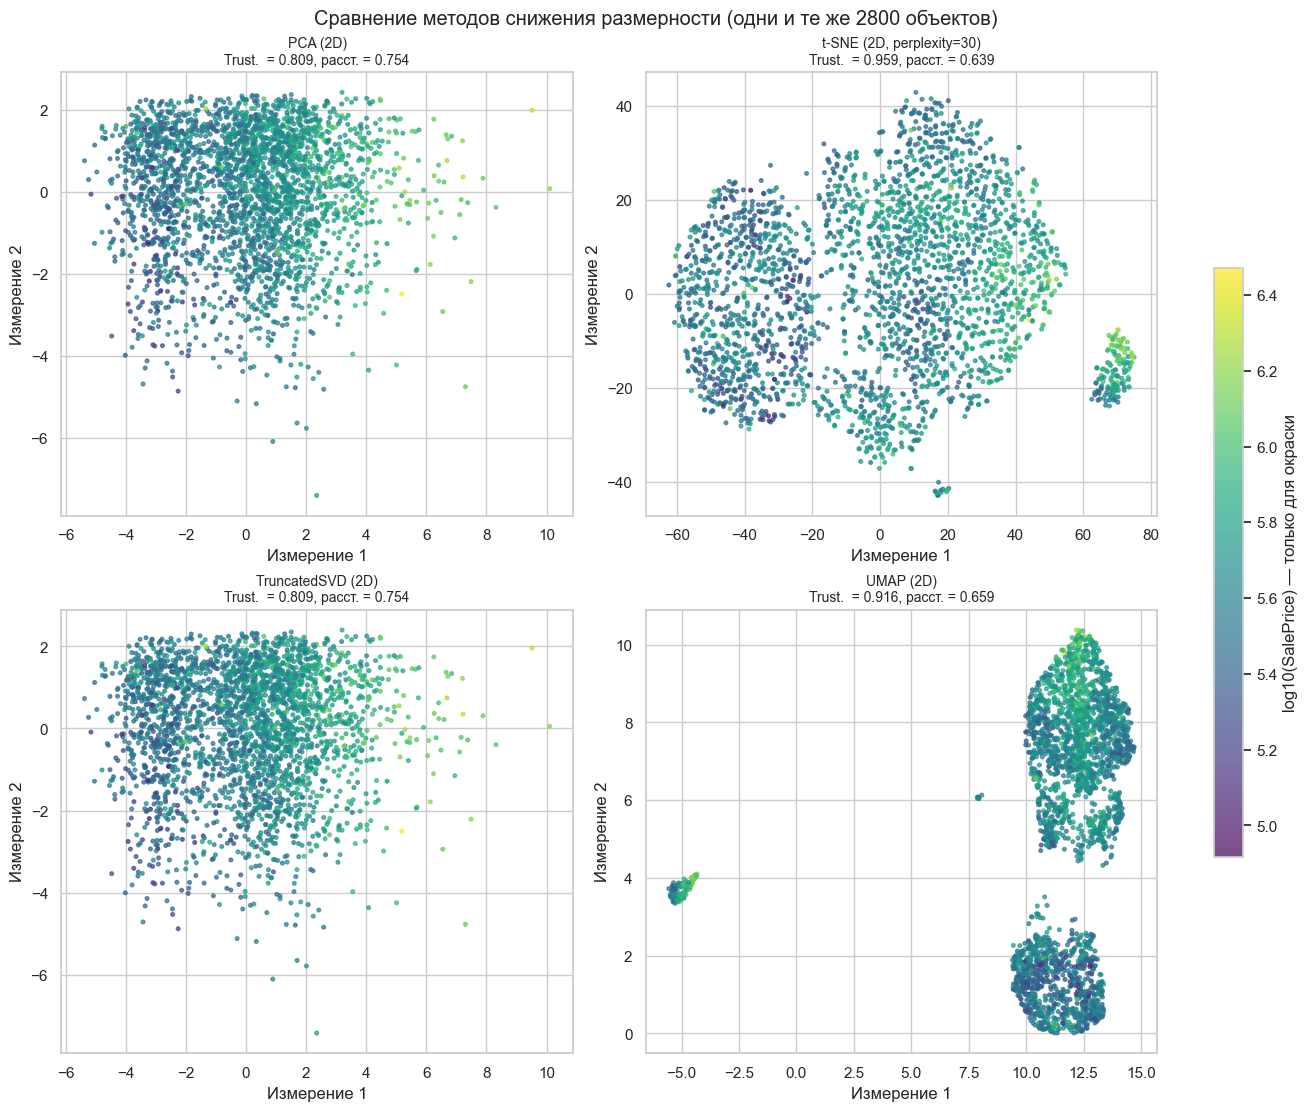

In [25]:
# Сравнительный вывод визуализаций: все методы рядом (одни и те же объекты, окраска по цене)
names = list(emb)
fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
for ax, name in zip(axes.ravel(), names):
    Z = emb[name]
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=log_price, cmap="viridis", s=7, alpha=0.7)
    ax.set_title(f"{name}\nTrust.  = {scores.loc[name, 'Trustworthiness']}, "
                 f"расст. = {scores.loc[name, 'Корреляция расстояний']}", fontsize=10)
    ax.set_xlabel("Измерение 1")
    ax.set_ylabel("Измерение 2")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
fig.colorbar(sc, ax=axes, label="log10(SalePrice) — только для окраски", shrink=0.6)
fig.suptitle("Сравнение методов снижения размерности (одни и те же 2800 объектов)")
plt.show()

In [26]:
# Сколько информации о цене «видно» в 2D: корреляция с ценой только для интерпретации (цена в методы не передавалась)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
res = {}
for name, Z in emb.items():
    r2 = cross_val_score(KNeighborsRegressor(n_neighbors=15), Z, log_price, cv=5, scoring="r2").mean()
    res[name] = round(r2, 3)
print("R² восстановления log10(цены) по 2D-координатам (kNN, 5-fold). Это лишь индикатор, не обучение методов на цене:")
print(pd.Series(res).to_string())

R² восстановления log10(цены) по 2D-координатам (kNN, 5-fold). Это лишь индикатор, не обучение методов на цене:
PCA (2D)                     0.425
t-SNE (2D, perplexity=30)    0.547
TruncatedSVD (2D)            0.424
UMAP (2D)                    0.512


### Проверка: что именно «видят» методы
Окрасим те же 2D-представления по **типу недвижимости** (`PropertyType`; он, как и цена, в методы не передавался) и посчитаем, насколько точно тип восстанавливается по двум координатам (kNN, 5-fold). Так наблюдение на графике (отдельные группы) превращается в расчётный показатель.

PropertyType
House/Villa         1129
Apartment            909
Townhouse/Duplex     762

Точность восстановления типа недвижимости по 2D-координатам (доля самого частого класса = 0.403 ):
PCA (2D)                     0.717
t-SNE (2D, perplexity=30)    0.797
TruncatedSVD (2D)            0.717
UMAP (2D)                    0.765


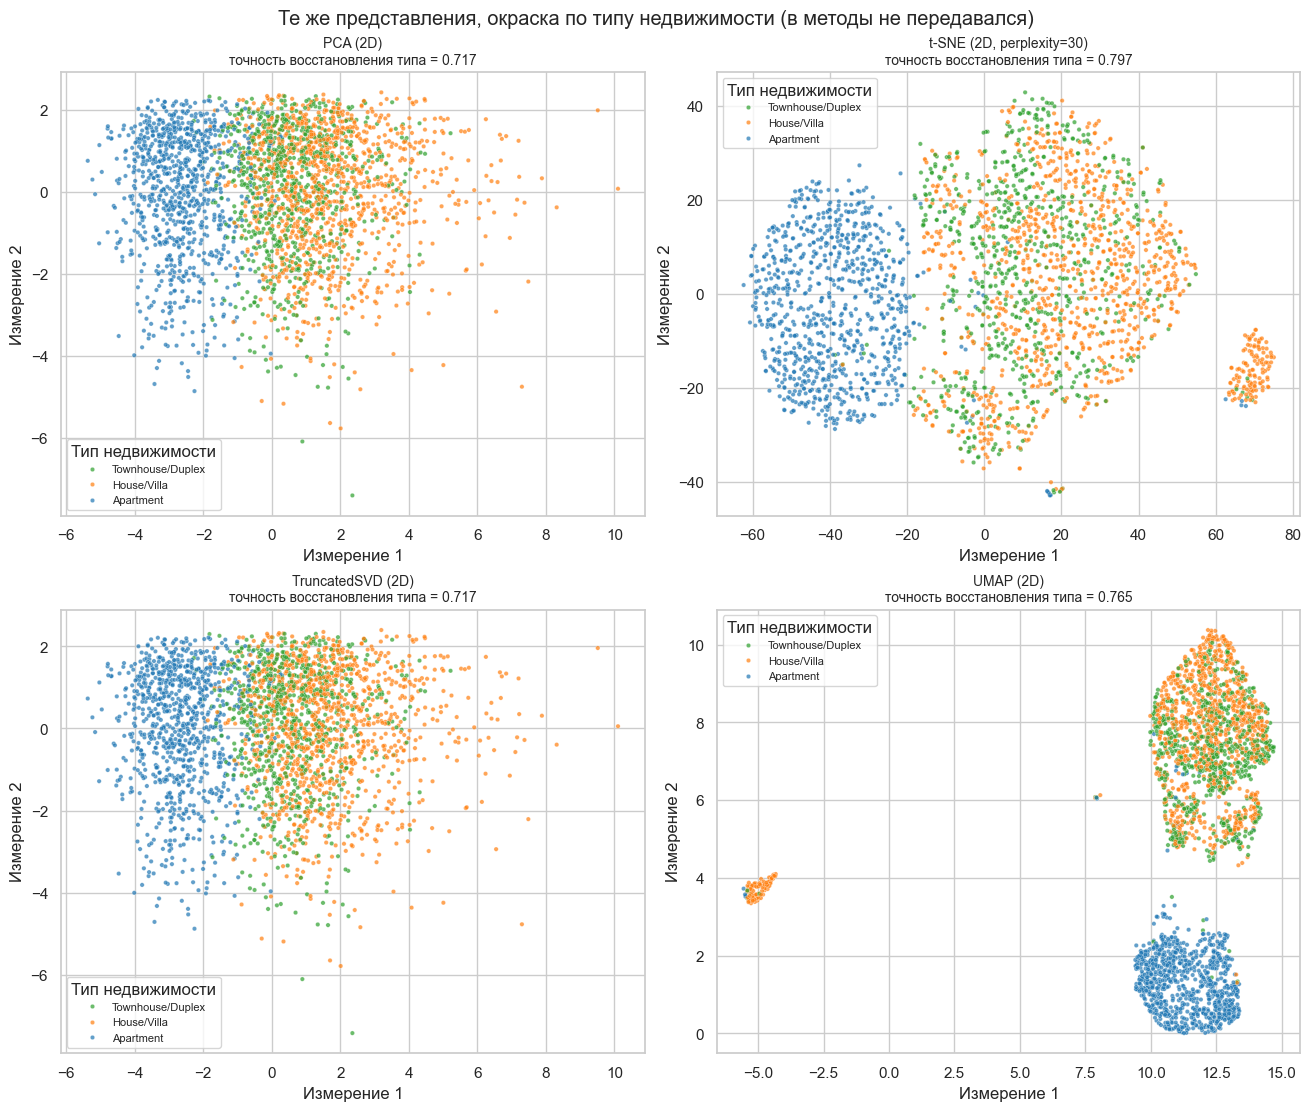

In [27]:
from sklearn.neighbors import KNeighborsClassifier

# Укрупняем типы: квартиры / дома и виллы / таунхаусы и дуплексы (редкий Penthouse относим к квартирам)
grp = df["PropertyType"].replace({"Penthouse": "Apartment", "Villa": "House/Villa", "House": "House/Villa",
                                  "Townhouse": "Townhouse/Duplex", "Duplex": "Townhouse/Duplex"})
print(grp.value_counts().to_string())

acc = {}
for name, Z in emb.items():
    acc[name] = round(cross_val_score(KNeighborsClassifier(15), Z, grp, cv=5, scoring="accuracy").mean(), 3)
print("\nТочность восстановления типа недвижимости по 2D-координатам (доля самого частого класса =",
      round(grp.value_counts(normalize=True).max(), 3), "):")
print(pd.Series(acc).to_string())

fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
palette = {"Apartment": "tab:blue", "House/Villa": "tab:orange", "Townhouse/Duplex": "tab:green"}
for ax, (name, Z) in zip(axes.ravel(), emb.items()):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=grp.values, palette=palette, s=10, alpha=0.7, ax=ax)
    ax.set_title(f"{name}\nточность восстановления типа = {acc[name]}", fontsize=10)
    ax.set_xlabel("Измерение 1")
    ax.set_ylabel("Измерение 2")
    ax.legend(title="Тип недвижимости", fontsize=8)
for ax in axes.ravel()[len(emb):]:
    ax.axis("off")
fig.suptitle("Те же представления, окраска по типу недвижимости (в методы не передавался)")
plt.show()

### Дополнительный эксперимент: помогает ли снижение размерности кластеризации
**Это отдельный эксперимент, он не относится к основной задаче снижения размерности.** Сравниваем K-Means с `k=4` при одинаковых условиях (`n_init=10`, `random_state=42`) на (а) исходных масштабированных признаках и (б) после PCA с сохранением 95% дисперсии.

Силуэты в разных пространствах напрямую не сравнимы, поэтому оцениваем **оба разбиения в одном и том же исходном пространстве** и дополнительно считаем согласованность разбиений (ARI) и время.

In [28]:
K = 4
pca95 = PCA(n_components=n95, random_state=RANDOM_STATE)
X_pca95 = pca95.fit_transform(X)
print(f"Размерность: исходная {X.shape[1]} -> после PCA {X_pca95.shape[1]}")

t0 = time.time(); lab_full = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(X); t_full = time.time() - t0
t0 = time.time(); lab_pca = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_pca95); t_pca = time.time() - t0

clu = pd.DataFrame({
    "Silhouette (в исходном пространстве)": [silhouette_score(X, lab_full), silhouette_score(X, lab_pca)],
    "Davies-Bouldin (в исходном пространстве)": [davies_bouldin_score(X, lab_full), davies_bouldin_score(X, lab_pca)],
    "Время K-Means, сек": [t_full, t_pca],
}, index=["Исходные признаки", f"PCA ({n95} компонент)"]).round(3)
print(clu.to_string())
print(f"\nСогласованность разбиений (ARI): {adjusted_rand_score(lab_full, lab_pca):.3f}")

Размерность: исходная 60 -> после PCA 31
                    Silhouette (в исходном пространстве)  Davies-Bouldin (в исходном пространстве)  Время K-Means, сек
Исходные признаки                                  0.098                                     2.455               0.061
PCA (31 компонент)                                 0.098                                     2.465               0.048

Согласованность разбиений (ARI): 0.975


**Как читать:** если ARI близок к 1, то после PCA K-Means находит практически те же группы, но быстрее и в меньшем числе измерений; если метрики качества почти не изменились, значит, отброшенные компоненты в основном содержали шум. Это показатель *практической пользы* снижения размерности.

## Интерпретация и обсуждение ограничений
> Числа ниже взяты из моего запуска. PCA детерминирован, t-SNE и UMAP при фиксированном `random_state` обычно воспроизводятся, но на другой версии библиотек могут слегка отличаться. Сверьте со своими выводами и поправьте, если нужно.

**1. Насколько удалось сократить размерность.** Исходная матрица — 60 признаков (19 числовых + 41 one-hot). PCA сохраняет 90% дисперсии на 23 компонентах (сжатие в ~2,6 раза) и 95% на 31 компоненте (в ~1,9 раза).

**2. Сколько компонент оставить.** Резкого «локтя» нет: первая компонента даёт 23%, дальше доли убывают плавно. Это значит, что информация в данных распределена по многим направлениям (многие one-hot признаки почти независимы). Целесообразно оставить **31 компоненту (95%)**: эксперимент с K-Means показал, что после такого сжатия разбиение практически то же (ARI ≈ 0,98), качество не изменилось (силуэт 0,098 против 0,098), а время вдвое меньше. Две компоненты (32,6% дисперсии) годятся только для визуализации, а не для анализа.

**3. Что означают компоненты PCA.**
- **PC1 (23%)** — «размер объекта»: площадь, спальни, комнаты, подвал, ванные (нагрузки около +0,3…+0,4). С ценой коррелирует 0,64.
- **PC2 (9,7%)** — «возраст и обновлённость»: год ремонта и энергоэффективность с одним знаком, возраст — с противоположным.
- **PC3 (8,5%)** — «гараж»: площадь и число мест в гараже.
- **PC4 (6,2%)** — «центральность и окружение»: расстояние до центра, преступность, школы, качество (корреляция с ценой −0,49).
Каждая компонента — комбинация многих признаков; она описывает *согласованное изменение* группы признаков, а не отдельный признак.

**4. Что видно на графиках (наблюдения) и чем это подтверждено расчётом.**
- PCA в 2D — сплошное облако без явных групп; две компоненты объясняют лишь 32,6% дисперсии, поэтому картинка отражает малую часть информации.
- t-SNE и UMAP показывают **отдельные «острова»**: небольшую компактную группу и крупную группу в стороне. Чтобы не судить по виду картинки, ноутбук считает, насколько по двум координатам восстанавливается тип недвижимости (kNN, 5-fold). В моём запуске точность 0,79 (t-SNE), 0,77 (UMAP) и 0,72 (PCA) при доле самого частого класса 0,40: нелинейные методы заметно лучше «упаковывают» тип объекта в 2D.
- Дополнительная ручная проверка (вне ноутбука, области выбраны по моему рисунку UMAP, поэтому на вашем запуске границы будут другими): левая верхняя группа почти целиком — квартиры (около 99%, участок `LotArea = 0`, высотные дома), а небольшой «остров» справа — в основном крупные дома и виллы (около 47% вилл, медианная площадь 200 м², медианная цена около 740 тыс.). Это **предположение, подкреплённое выборочной проверкой**, а не доказательство кластеров.
- Такое разделение объясняется данными: у квартир `LotArea = 0` и `TotalBsmtSF = 0`, у них много этажей и балконы, у вилл — большая площадь. Это свойство **синтетического** датасета, а не закон рынка.
- Цена на 2D-картах меняется плавно (в t-SNE и UMAP — в пределах групп), то есть методы сохранили информацию, связанную с ценой, хотя цена им не передавалась.

**5. Различия методов (по расчётным показателям).**
- Локальная структура: t-SNE (trustworthiness 0,959) > UMAP (0,913) > PCA (0,809).
- Глобальные расстояния: PCA (0,754) заметно выше UMAP (0,635) и t-SNE (0,638).
- Это ожидаемый компромисс: нелинейные методы лучше сохраняют соседей, PCA — общую геометрию. `TruncatedSVD` в 2D совпал с PCA (на данной таблице это почти одно и то же).

**6. Ограничения.** Это наблюдения и расчёты по одному синтетическому датасету. Для t-SNE и UMAP форма групп, размеры «островов» и расстояния между ними зависят от параметров (`perplexity`, `n_neighbors`, `min_dist`) и случайности — мы это показали на трёх значениях `perplexity`. Наличие островов не доказывает «настоящих кластеров»: мы подтвердили их связь с типом недвижимости отдельной проверкой, а не по виду картинки. PCA линеен и чувствителен к выбросам и масштабу; метрики trustworthiness и корреляция расстояний — упрощённые индикаторы. One-hot признаки в PCA ведут себя не так естественно, как числовые.

**7. Когда какой метод полезен.** PCA — сжатие признаков и подготовка к моделям, анализ факторов. t-SNE — визуальное исследование локальной структуры. UMAP — то же на больших данных, быстрее и с возможностью преобразовывать новые объекты. TruncatedSVD — разреженные данные (тексты, матрицы взаимодействий).


## Общие выводы
Автоматическая часть формируется по реальным результатам выше.

In [29]:
best_local = scores["Trustworthiness"].idxmax()
best_global = scores["Корреляция расстояний"].idxmax()
print(f"Объектов: {len(df)}. Признаков до преобразования: {X.shape[1]} ({len(num_cols)} числовых + {len(cat_names)} one-hot).")
print(f"PCA: 90% дисперсии сохраняют {n90} компонент, 95% — {n95} (сокращение размерности в {X.shape[1] / n90:.1f} и {X.shape[1] / n95:.1f} раза).")
print(f"Первые две компоненты PCA сохраняют {evr[:2].sum() * 100:.1f}% дисперсии.")
print(f"Лучшее сохранение локальной структуры (trustworthiness): {best_local} ({scores.loc[best_local, 'Trustworthiness']}).")
print(f"Лучшее сохранение глобальных расстояний: {best_global} ({scores.loc[best_global, 'Корреляция расстояний']}).")
print(f"K-Means до и после PCA({n95}) даёт разбиения с ARI = {adjusted_rand_score(lab_full, lab_pca):.2f}; "
      f"время {t_full:.2f} сек против {t_pca:.2f} сек.")

Объектов: 2800. Признаков до преобразования: 60 (19 числовых + 41 one-hot).
PCA: 90% дисперсии сохраняют 23 компонент, 95% — 31 (сокращение размерности в 2.6 и 1.9 раза).
Первые две компоненты PCA сохраняют 32.6% дисперсии.
Лучшее сохранение локальной структуры (trustworthiness): t-SNE (2D, perplexity=30) (0.959).
Лучшее сохранение глобальных расстояний: PCA (2D) (0.754).
K-Means до и после PCA(31) даёт разбиения с ARI = 0.98; время 0.06 сек против 0.05 сек.
